<a href="https://colab.research.google.com/github/khushiTalele/RAG-Implementation-Project/blob/main/PDS_PBL3ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q pypdf sentence-transformers faiss-cpu pandas numpy matplotlib

In [ ]:
# STEP 3: Create our knowledge base

documents = [
    "Refunds are allowed within 7 days of purchase.",
    "Our support team is available 24/7 via chat.",
    "Premium plans include priority email support."
]

print("Number of documents:", len(documents))

for i, doc in enumerate(documents, 1):
    print(f"Document {i}: {doc}")

Number of documents: 3
Document 1: Refunds are allowed within 7 days of purchase.
Document 2: Our support team is available 24/7 via chat.
Document 3: Premium plans include priority email support.


In [ ]:
# STEP 4: Text Chunking

def create_chunks(text, chunk_size=50):
    chunks = []

    for i in range(0, len(text), chunk_size):
        chunk = text[i:i + chunk_size]
        chunks.append(chunk)

    return chunks


# Create chunks for all documents
all_chunks = []

for doc in documents:
    chunks = create_chunks(doc)
    all_chunks.extend(chunks)

print("Total chunks created:", len(all_chunks))

print("\nChunks:")
for i, chunk in enumerate(all_chunks, 1):
    print(f"Chunk {i}: {chunk}")

Total chunks created: 3

Chunks:
Chunk 1: Refunds are allowed within 7 days of purchase.
Chunk 2: Our support team is available 24/7 via chat.
Chunk 3: Premium plans include priority email support.


In [ ]:
# STEP 5: Create Embeddings

from sentence_transformers import SentenceTransformer

# Load the embedding model
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

# Convert our chunks into numerical vectors
embeddings = embedding_model.encode(all_chunks)

print("Number of chunks:", len(all_chunks))
print("Embedding shape:", embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Number of chunks: 3
Embedding shape: (3, 384)


In [ ]:
# STEP 6: Create FAISS Vector Database

import faiss
import numpy as np

# Convert embeddings to float32
embedding_vectors = np.array(embeddings).astype("float32")

# Get the number of dimensions
dimension = embedding_vectors.shape[1]

# Create FAISS index
index = faiss.IndexFlatL2(dimension)

# Add our embeddings to the index
index.add(embedding_vectors)

print("Vector database created successfully!")
print("Number of vectors stored:", index.ntotal)
print("Vector dimension:", dimension)

Vector database created successfully!
Number of vectors stored: 3
Vector dimension: 384


In [ ]:
# STEP 7: Retrieve Relevant Information

question = "What is the refund period?"

# Convert the question into an embedding
question_embedding = embedding_model.encode([question])
question_embedding = np.array(question_embedding).astype("float32")

# Search the vector database
k = 1
distances, indices = index.search(question_embedding, k)

# Get the most relevant chunk
retrieved_chunk = all_chunks[indices[0][0]]

print("User Question:")
print(question)

print("\nRetrieved Information:")
print(retrieved_chunk)

print("\nSimilarity Search Distance:")
print(distances[0][0])

User Question:
What is the refund period?

Retrieved Information:
Refunds are allowed within 7 days of purchase.

Similarity Search Distance:
0.72706735


In [ ]:
# STEP 8: Create a reusable retrieval function

def retrieve(question, k=1):
    # Convert question into embedding
    question_embedding = embedding_model.encode([question])
    question_embedding = np.array(question_embedding).astype("float32")

    # Search vector database
    distances, indices = index.search(question_embedding, k)

    # Get retrieved chunks
    results = []

    for i in range(k):
        results.append({
            "chunk": all_chunks[indices[0][i]],
            "distance": float(distances[0][i])
        })

    return results


# Test the function
question = "How long do I have to request a refund?"

results = retrieve(question)

print("Question:", question)

for i, result in enumerate(results, 1):
    print(f"\nResult {i}:")
    print("Information:", result["chunk"])
    print("Distance:", result["distance"])

Question: How long do I have to request a refund?

Result 1:
Information: Refunds are allowed within 7 days of purchase.
Distance: 0.5645210146903992


In [ ]:
# STEP 9: Augmentation - Prepare retrieved context

question = "How long do I have to request a refund?"

# Retrieve relevant information
results = retrieve(question, k=1)

# Extract the retrieved information
context = results[0]["chunk"]

print("QUESTION:")
print(question)

print("\nRETRIEVED CONTEXT:")
print(context)

# Create the prompt that will be given to the language model
prompt = f"""
Use the following context to answer the question.

Context:
{context}

Question:
{question}

Answer:
"""

print("\nPROMPT FOR LANGUAGE MODEL:")
print(prompt)

QUESTION:
How long do I have to request a refund?

RETRIEVED CONTEXT:
Refunds are allowed within 7 days of purchase.

PROMPT FOR LANGUAGE MODEL:

Use the following context to answer the question.

Context:
Refunds are allowed within 7 days of purchase.

Question:
How long do I have to request a refund?

Answer:



In [ ]:
# STEP 10A: Install language model libraries

!pip install -q transformers sentencepiece

In [ ]:
# STEP 10B: Load the language model - corrected version

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "google/flan-t5-small"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load language model
generator_model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

print("Language model loaded successfully!")

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Language model loaded successfully!


In [ ]:
# STEP 10C: Generate the final RAG answer

question = "How long do I have to request a refund?"

# Retrieve relevant information
results = retrieve(question, k=1)

# Get the retrieved context
context = results[0]["chunk"]

# Create the RAG prompt
prompt = f"""
Use the following context to answer the question.
Answer only using the information provided in the context.

Context:
{context}

Question:
{question}

Answer:
"""

# Convert prompt into tokens
inputs = tokenizer(
    prompt,
    return_tensors="pt",
    truncation=True
)

# Generate answer
outputs = generator_model.generate(
    **inputs,
    max_new_tokens=50
)

# Convert generated tokens back to text
answer = tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("QUESTION:")
print(question)

print("\nRETRIEVED CONTEXT:")
print(context)

print("\nGENERATED ANSWER:")
print(answer)

QUESTION:
How long do I have to request a refund?

RETRIEVED CONTEXT:
Refunds are allowed within 7 days of purchase.

GENERATED ANSWER:
(ii)


In [ ]:
# STEP 10D: Improved RAG generation

question = "How long do I have to request a refund?"

# Retrieve relevant information
results = retrieve(question, k=1)

# Get context
context = results[0]["chunk"]

# Simpler prompt for FLAN-T5
prompt = f"""
Answer the question using only the context below.

Context: {context}

Question: {question}

Answer:
"""

# Tokenize
inputs = tokenizer(
    prompt,
    return_tensors="pt",
    truncation=True
)

# Generate a better answer
outputs = generator_model.generate(
    **inputs,
    max_new_tokens=30,
    num_beams=4,
    do_sample=False,
    early_stopping=True
)

# Decode
answer = tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("QUESTION:")
print(question)

print("\nRETRIEVED CONTEXT:")
print(context)

print("\nGENERATED ANSWER:")
print(answer)

QUESTION:
How long do I have to request a refund?

RETRIEVED CONTEXT:
Refunds are allowed within 7 days of purchase.

GENERATED ANSWER:
within 7 days


In [ ]:
# STEP 11: Test multiple questions

test_questions = [
    "How long do I have to request a refund?",
    "What is the refund period?",
    "Can I get a refund after buying something?",
    "Is customer support available all day?",
    "How can I contact the support team?",
    "When is the support team available?",
    "What does the premium plan include?",
    "Do premium users get priority email support?",
    "What kind of support does the premium plan provide?",
    "How can I get help from customer support?"
]

results_table = []

for question in test_questions:

    # Retrieve relevant chunk
    results = retrieve(question, k=1)

    retrieved_text = results[0]["chunk"]
    distance = results[0]["distance"]

    # Create prompt
    prompt = f"""
Answer the question using only the context below.

Context: {retrieved_text}

Question: {question}

Answer:
"""

    # Generate answer
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True
    )

    outputs = generator_model.generate(
        **inputs,
        max_new_tokens=30,
        num_beams=4,
        do_sample=False,
        early_stopping=True
    )

    answer = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    results_table.append({
        "Question": question,
        "Retrieved Information": retrieved_text,
        "Distance": distance,
        "Generated Answer": answer
    })


# Display results
import pandas as pd

results_df = pd.DataFrame(results_table)

pd.set_option("display.max_colwidth", 100)

results_df

,Question,Retrieved Information,Distance,Generated Answer
0,How long do I have to request a refund?,Refunds are allowed within 7 days of purchase.,0.564521,within 7 days
1,What is the refund period?,Refunds are allowed within 7 days of purchase.,0.727067,within 7 days
2,Can I get a refund after buying something?,Refunds are allowed within 7 days of purchase.,0.634314,Yes
3,Is customer support available all day?,Our support team is available 24/7 via chat.,0.795661,Yes
4,How can I contact the support team?,Our support team is available 24/7 via chat.,0.779947,Chat
5,When is the support team available?,Our support team is available 24/7 via chat.,0.541739,24/7
6,What does the premium plan include?,Premium plans include priority email support.,0.632938,priority email support
7,Do premium users get priority email support?,Premium plans include priority email support.,0.244449,yes
8,What kind of support does the premium plan provide?,Premium plans include priority email support.,0.547093,priority email support
9,How can I get help from customer support?,Our support team is available 24/7 via chat.,1.252346,chat


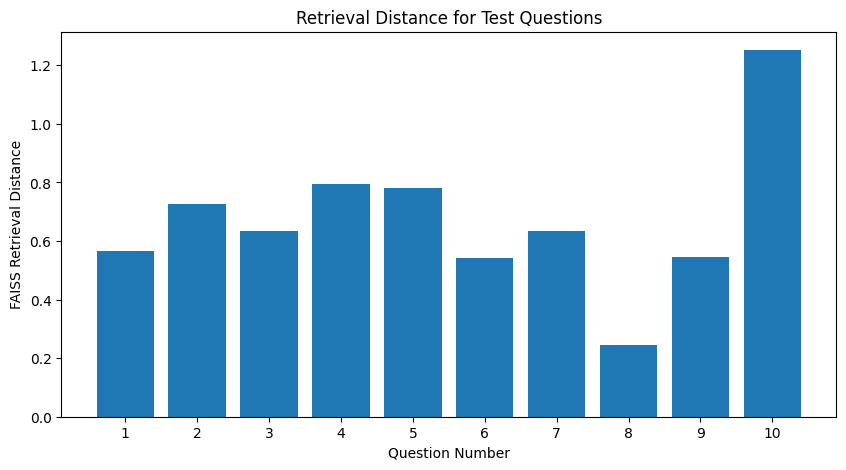

In [ ]:
# STEP 12: Retrieval Distance Graph

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    range(1, len(results_df) + 1),
    results_df["Distance"]
)

plt.xlabel("Question Number")
plt.ylabel("FAISS Retrieval Distance")
plt.title("Retrieval Distance for Test Questions")
plt.xticks(range(1, len(results_df) + 1))

plt.show()

In [ ]:
# STEP 13: RAG Retrieval Evaluation

expected_sources = [
    "refund",
    "refund",
    "refund",
    "support",
    "support",
    "support",
    "premium",
    "premium",
    "premium",
    "support"
]

# Check whether the retrieved information matches
# the expected topic
results_df["Expected Topic"] = expected_sources

results_df["Retrieved Correctly"] = results_df.apply(
    lambda row: row["Expected Topic"].lower()
    in row["Retrieved Information"].lower(),
    axis=1
)

# Display evaluation table
evaluation_df = results_df[
    [
        "Question",
        "Expected Topic",
        "Retrieved Information",
        "Distance",
        "Retrieved Correctly",
        "Generated Answer"
    ]
]

evaluation_df

,Question,Expected Topic,Retrieved Information,Distance,Retrieved Correctly,Generated Answer
0,How long do I have to request a refund?,refund,Refunds are allowed within 7 days of purchase.,0.564521,True,within 7 days
1,What is the refund period?,refund,Refunds are allowed within 7 days of purchase.,0.727067,True,within 7 days
2,Can I get a refund after buying something?,refund,Refunds are allowed within 7 days of purchase.,0.634314,True,Yes
3,Is customer support available all day?,support,Our support team is available 24/7 via chat.,0.795661,True,Yes
4,How can I contact the support team?,support,Our support team is available 24/7 via chat.,0.779947,True,Chat
5,When is the support team available?,support,Our support team is available 24/7 via chat.,0.541739,True,24/7
6,What does the premium plan include?,premium,Premium plans include priority email support.,0.632938,True,priority email support
7,Do premium users get priority email support?,premium,Premium plans include priority email support.,0.244449,True,yes
8,What kind of support does the premium plan provide?,premium,Premium plans include priority email support.,0.547093,True,priority email support
9,How can I get help from customer support?,support,Our support team is available 24/7 via chat.,1.252346,True,chat


In [ ]:
# STEP 14: Calculate Retrieval Topic-Match Rate

correct_retrievals = evaluation_df["Retrieved Correctly"].sum()
total_questions = len(evaluation_df)

retrieval_match_rate = (correct_retrievals / total_questions) * 100

print("Total Test Questions:", total_questions)
print("Correct Topic Matches:", correct_retrievals)
print(f"Retrieval Topic-Match Rate: {retrieval_match_rate:.2f}%")

Total Test Questions: 10
Correct Topic Matches: 10
Retrieval Topic-Match Rate: 100.00%


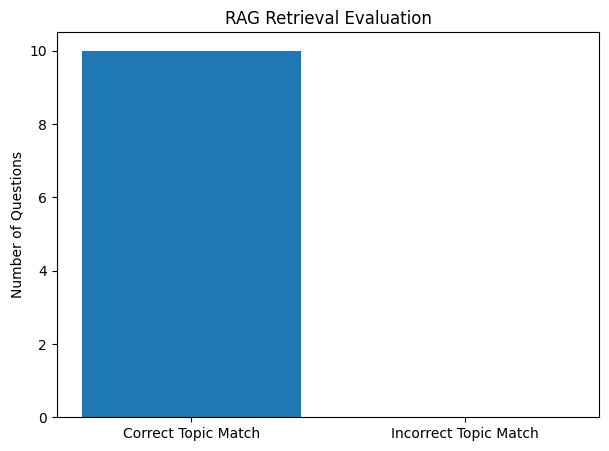

In [ ]:
# STEP 15: Retrieval Evaluation Graph

import matplotlib.pyplot as plt

correct = evaluation_df["Retrieved Correctly"].sum()
incorrect = len(evaluation_df) - correct

labels = ["Correct Topic Match", "Incorrect Topic Match"]
values = [correct, incorrect]

plt.figure(figsize=(7, 5))

plt.bar(labels, values)

plt.ylabel("Number of Questions")
plt.title("RAG Retrieval Evaluation")

plt.show()

In [ ]:
# STEP 16: Test an unknown question

unknown_question = "What is the price of the premium plan?"

results = retrieve(unknown_question, k=1)

print("QUESTION:")
print(unknown_question)

print("\nRETRIEVED INFORMATION:")
print(results[0]["chunk"])

print("\nDISTANCE:")
print(results[0]["distance"])

QUESTION:
What is the price of the premium plan?

RETRIEVED INFORMATION:
Premium plans include priority email support.

DISTANCE:
0.8341941833496094


In [ ]:
# STEP 17: Add a relevance threshold

DISTANCE_THRESHOLD = 0.80

def retrieve_with_threshold(question, k=1):
    results = retrieve(question, k)

    best_result = results[0]

    if best_result["distance"] <= DISTANCE_THRESHOLD:
        return best_result, True
    else:
        return best_result, False


# Test the unknown question
question = "What is the price of the premium plan?"

result, relevant = retrieve_with_threshold(question)

print("QUESTION:")
print(question)

print("\nRETRIEVED INFORMATION:")
print(result["chunk"])

print("\nDISTANCE:")
print(result["distance"])

print("\nSufficiently Relevant:")
print(relevant)

QUESTION:
What is the price of the premium plan?

RETRIEVED INFORMATION:
Premium plans include priority email support.

DISTANCE:
0.8341941833496094

Sufficiently Relevant:
False


In [ ]:
# STEP 18: Test questions outside the knowledge base

unknown_questions = [
    "What is the price of the premium plan?",
    "How can I cancel my subscription?",
    "Does the company offer a mobile application?",
    "What payment methods are accepted?",
    "Is there a free trial available?"
]

unknown_results = []

for question in unknown_questions:

    results = retrieve(question, k=1)

    unknown_results.append({
        "Question": question,
        "Retrieved Information": results[0]["chunk"],
        "Distance": results[0]["distance"]
    })

unknown_df = pd.DataFrame(unknown_results)

unknown_df


,Question,Retrieved Information,Distance
0,What is the price of the premium plan?,Premium plans include priority email support.,0.834194
1,How can I cancel my subscription?,Premium plans include priority email support.,1.383923
2,Does the company offer a mobile application?,Premium plans include priority email support.,1.395302
3,What payment methods are accepted?,Refunds are allowed within 7 days of purchase.,1.462667
4,Is there a free trial available?,Premium plans include priority email support.,1.526402


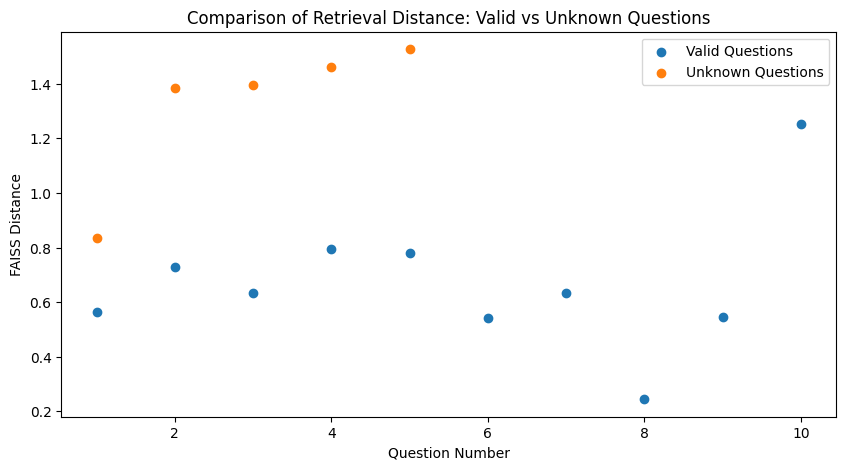

In [ ]:
# STEP 19: Compare valid and unknown question distances

import matplotlib.pyplot as plt

valid_distances = evaluation_df["Distance"]
unknown_distances = unknown_df["Distance"]

plt.figure(figsize=(10, 5))

plt.scatter(
    range(1, len(valid_distances) + 1),
    valid_distances,
    label="Valid Questions"
)

plt.scatter(
    range(1, len(unknown_distances) + 1),
    unknown_distances,
    label="Unknown Questions"
)

plt.xlabel("Question Number")
plt.ylabel("FAISS Distance")
plt.title("Comparison of Retrieval Distance: Valid vs Unknown Questions")
plt.legend()

plt.show()

In [ ]:
# STEP 20A: Expanded Knowledge Base

documents = [
    "Refunds are allowed within 7 days of purchase.",
    "Customers can request a refund by contacting customer support.",
    "Refund requests must be submitted within the allowed refund period.",
    "Refunds are processed after the request is reviewed.",
    "Customer support is available 24/7 via chat.",
    "Customers can contact the support team through the online chat.",
    "The support team helps customers with product and account-related questions.",
    "Support requests can be submitted through the customer support channel.",
    "Premium plans include priority email support.",
    "Premium customers receive priority assistance through email.",
    "The premium plan provides additional customer support benefits.",
    "Premium users can access priority support services.",
    "Customers should contact support if they have questions about their account.",
    "The support team can help with refund-related questions.",
    "Customers should provide relevant purchase information when requesting support."
]

print("Number of documents:", len(documents))

for i, doc in enumerate(documents, 1):
    print(f"Document {i}: {doc}")

Number of documents: 15
Document 1: Refunds are allowed within 7 days of purchase.
Document 2: Customers can request a refund by contacting customer support.
Document 3: Refund requests must be submitted within the allowed refund period.
Document 4: Refunds are processed after the request is reviewed.
Document 5: Customer support is available 24/7 via chat.
Document 6: Customers can contact the support team through the online chat.
Document 7: The support team helps customers with product and account-related questions.
Document 8: Support requests can be submitted through the customer support channel.
Document 9: Premium plans include priority email support.
Document 10: Premium customers receive priority assistance through email.
Document 11: The premium plan provides additional customer support benefits.
Document 12: Premium users can access priority support services.
Document 13: Customers should contact support if they have questions about their account.
Document 14: The support te

In [ ]:
# STEP 20B: Create chunks from the expanded knowledge base

chunks = []

for doc in documents:
    # Each document is already short,
    # so each document becomes one chunk.
    chunks.append(doc)

print("Total chunks created:", len(chunks))

print("\nChunks:")

for i, chunk in enumerate(chunks, 1):
    print(f"Chunk {i}: {chunk}")

Total chunks created: 15

Chunks:
Chunk 1: Refunds are allowed within 7 days of purchase.
Chunk 2: Customers can request a refund by contacting customer support.
Chunk 3: Refund requests must be submitted within the allowed refund period.
Chunk 4: Refunds are processed after the request is reviewed.
Chunk 5: Customer support is available 24/7 via chat.
Chunk 6: Customers can contact the support team through the online chat.
Chunk 7: The support team helps customers with product and account-related questions.
Chunk 8: Support requests can be submitted through the customer support channel.
Chunk 9: Premium plans include priority email support.
Chunk 10: Premium customers receive priority assistance through email.
Chunk 11: The premium plan provides additional customer support benefits.
Chunk 12: Premium users can access priority support services.
Chunk 13: Customers should contact support if they have questions about their account.
Chunk 14: The support team can help with refund-related 

In [ ]:
# STEP 20C: Generate embeddings for all chunks

from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

embeddings = embedding_model.encode(chunks)

print("Number of chunks:", len(chunks))
print("Embedding shape:", embeddings.shape)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Number of chunks: 15
Embedding shape: (15, 384)


In [ ]:
# STEP 20D: Create FAISS vector database

import faiss
import numpy as np

# Convert embeddings to float32
embedding_vectors = np.array(embeddings).astype("float32")

# Create FAISS index
dimension = embedding_vectors.shape[1]

index = faiss.IndexFlatL2(dimension)

# Add embeddings to FAISS
index.add(embedding_vectors)

print("Vector database created successfully!")
print("Number of vectors stored:", index.ntotal)
print("Vector dimension:", dimension)

ModuleNotFoundError: No module named 'faiss'

In [ ]:
!pip install -q faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 26.6 MB/s eta 0:00:00


In [ ]:
import faiss
import numpy as np

embedding_vectors = np.array(embeddings).astype("float32")

dimension = embedding_vectors.shape[1]

index = faiss.IndexFlatL2(dimension)

index.add(embedding_vectors)

print("Vector database created successfully!")
print("Number of vectors stored:", index.ntotal)
print("Vector dimension:", dimension)

NameError: name 'embeddings' is not defined

In [ ]:
documents = [
    "Refunds are allowed within 7 days of purchase.",
    "Customers can request a refund by contacting customer support.",
    "Refund requests must be submitted within the allowed refund period.",
    "Refunds are processed after the request is reviewed.",
    "Customer support is available 24/7 via chat.",
    "Customers can contact the support team through the online chat.",
    "The support team helps customers with product and account-related questions.",
    "Support requests can be submitted through the customer support channel.",
    "Premium plans include priority email support.",
    "Premium customers receive priority assistance through email.",
    "The premium plan provides additional customer support benefits.",
    "Premium users can access priority support services.",
    "Customers should contact support if they have questions about their account.",
    "The support team can help with refund-related questions.",
    "Customers should provide relevant purchase information when requesting support."
]

chunks = documents.copy()

print("Total chunks created:", len(chunks))

for i, chunk in enumerate(chunks, 1):
    print(f"Chunk {i}: {chunk}")

Total chunks created: 15
Chunk 1: Refunds are allowed within 7 days of purchase.
Chunk 2: Customers can request a refund by contacting customer support.
Chunk 3: Refund requests must be submitted within the allowed refund period.
Chunk 4: Refunds are processed after the request is reviewed.
Chunk 5: Customer support is available 24/7 via chat.
Chunk 6: Customers can contact the support team through the online chat.
Chunk 7: The support team helps customers with product and account-related questions.
Chunk 8: Support requests can be submitted through the customer support channel.
Chunk 9: Premium plans include priority email support.
Chunk 10: Premium customers receive priority assistance through email.
Chunk 11: The premium plan provides additional customer support benefits.
Chunk 12: Premium users can access priority support services.
Chunk 13: Customers should contact support if they have questions about their account.
Chunk 14: The support team can help with refund-related questions

In [ ]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

embeddings = embedding_model.encode(chunks)

print("Number of chunks:", len(chunks))
print("Embedding shape:", embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Number of chunks: 15
Embedding shape: (15, 384)


In [ ]:
import faiss
import numpy as np

embedding_vectors = np.array(embeddings).astype("float32")

dimension = embedding_vectors.shape[1]

index = faiss.IndexFlatL2(dimension)

index.add(embedding_vectors)

print("Vector database created successfully!")
print("Number of vectors stored:", index.ntotal)
print("Vector dimension:", dimension)

Vector database created successfully!
Number of vectors stored: 15
Vector dimension: 384


In [ ]:
question = "How long do I have to request a refund?"

results = retrieve(question, k=1)

print("Question:", question)
print("\nRetrieved Information:")
print(results[0]["chunk"])
print("\nDistance:", results[0]["distance"])


NameError: name 'retrieve' is not defined

In [ ]:
def retrieve(question, k=1):
    question_embedding = embedding_model.encode([question])
    question_embedding = np.array(question_embedding).astype("float32")

    distances, indices = index.search(question_embedding, k)

    results = []

    for i in range(k):
        results.append({
            "chunk": chunks[indices[0][i]],
            "distance": float(distances[0][i])
        })

    return results

print("Retrieval function created successfully!")

Retrieval function created successfully!


In [ ]:
question = "How long do I have to request a refund?"

results = retrieve(question, k=1)

print("Question:", question)
print("\nRetrieved Information:")
print(results[0]["chunk"])
print("\nDistance:", results[0]["distance"])

Question: How long do I have to request a refund?

Retrieved Information:
Refunds are allowed within 7 days of purchase.

Distance: 0.5645211338996887


In [ ]:
test_questions = [
    "Is customer support available all day?",
    "What does the premium plan include?",
    "How can I contact the support team?"
]

for question in test_questions:
    results = retrieve(question, k=1)

    print("Question:", question)
    print("Retrieved:", results[0]["chunk"])
    print("Distance:", results[0]["distance"])
    print("-" * 60)

Question: Is customer support available all day?
Retrieved: Customer support is available 24/7 via chat.
Distance: 0.4116760492324829
------------------------------------------------------------
Question: What does the premium plan include?
Retrieved: The premium plan provides additional customer support benefits.
Distance: 0.3783457279205322
------------------------------------------------------------
Question: How can I contact the support team?
Retrieved: Customers can contact the support team through the online chat.
Distance: 0.5290873050689697
------------------------------------------------------------


In [ ]:
question = "How long do I have to request a refund?"

results = retrieve(question, k=1)
context = results[0]["chunk"]

prompt = f"""
Answer the question using only the context below.

Context:
{context}

Question:
{question}

Answer:
"""

inputs = tokenizer(prompt, return_tensors="pt", truncation=True)

outputs = generator_model.generate(
    **inputs,
    max_new_tokens=30,
    num_beams=4,
    do_sample=False,
    early_stopping=True
)

answer = tokenizer.decode(outputs[0], skip_special_tokens=True)

print("Question:", question)
print("\nRetrieved Context:", context)
print("\nGenerated Answer:", answer)

NameError: name 'tokenizer' is not defined

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "google/flan-t5-small"

tokenizer = AutoTokenizer.from_pretrained(model_name)

generator_model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

print("Tokenizer loaded successfully!")
print("Language model loaded successfully!")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Tokenizer loaded successfully!
Language model loaded successfully!


In [ ]:
question = "How long do I have to request a refund?"

results = retrieve(question, k=1)
context = results[0]["chunk"]

prompt = f"""
Answer the question using only the context below.

Context:
{context}

Question:
{question}

Answer:
"""

inputs = tokenizer(prompt, return_tensors="pt", truncation=True)

outputs = generator_model.generate(
    **inputs,
    max_new_tokens=30,
    num_beams=4,
    do_sample=False,
    early_stopping=True
)

answer = tokenizer.decode(outputs[0], skip_special_tokens=True)

print("Question:", question)
print("\nRetrieved Context:", context)
print("\nGenerated Answer:", answer)

Question: How long do I have to request a refund?

Retrieved Context: Refunds are allowed within 7 days of purchase.

Generated Answer: within 7 days


In [ ]:
test_questions = [
    "How long do I have to request a refund?",
    "Is customer support available all day?",
    "How can I contact the support team?",
    "What does the premium plan include?",
    "Do premium users get priority support?"
]

for question in test_questions:

    results = retrieve(question, k=1)
    context = results[0]["chunk"]

    prompt = f"""
Answer the question using only the context below.

Context:
{context}

Question:
{question}

Answer:
"""

    inputs = tokenizer(prompt, return_tensors="pt", truncation=True)

    outputs = generator_model.generate(
        **inputs,
        max_new_tokens=30,
        num_beams=4,
        do_sample=False,
        early_stopping=True
    )

    answer = tokenizer.decode(outputs[0], skip_special_tokens=True)

    print("Question:", question)
    print("Retrieved:", context)
    print("Answer:", answer)
    print("-" * 70)

Question: How long do I have to request a refund?
Retrieved: Refunds are allowed within 7 days of purchase.
Answer: within 7 days
----------------------------------------------------------------------
Question: Is customer support available all day?
Retrieved: Customer support is available 24/7 via chat.
Answer: 24/7
----------------------------------------------------------------------
Question: How can I contact the support team?
Retrieved: Customers can contact the support team through the online chat.
Answer: through the online chat
----------------------------------------------------------------------
Question: What does the premium plan include?
Retrieved: The premium plan provides additional customer support benefits.
Answer: additional customer support benefits
----------------------------------------------------------------------
Question: Do premium users get priority support?
Retrieved: Premium users can access priority support services.
Answer: yes
-------------------------

In [ ]:
import pandas as pd

test_questions = [
    "How long do I have to request a refund?",
    "Is customer support available all day?",
    "How can I contact the support team?",
    "What does the premium plan include?",
    "Do premium users get priority support?"
]

rag_results = []

for question in test_questions:

    results = retrieve(question, k=1)
    context = results[0]["chunk"]
    distance = results[0]["distance"]

    prompt = f"""
Answer the question using only the context below.

Context:
{context}

Question:
{question}

Answer:
"""

    inputs = tokenizer(prompt, return_tensors="pt", truncation=True)

    outputs = generator_model.generate(
        **inputs,
        max_new_tokens=30,
        num_beams=4,
        do_sample=False,
        early_stopping=True
    )

    answer = tokenizer.decode(outputs[0], skip_special_tokens=True)

    rag_results.append({
        "Question": question,
        "Retrieved Context": context,
        "Distance": distance,
        "Generated Answer": answer
    })

rag_df = pd.DataFrame(rag_results)

print("RAG results stored successfully!")
display(rag_df)

RAG results stored successfully!


,Question,Retrieved Context,Distance,Generated Answer
0,How long do I have to request a refund?,Refunds are allowed within 7 days of purchase.,0.564521,within 7 days
1,Is customer support available all day?,Customer support is available 24/7 via chat.,0.411676,24/7
2,How can I contact the support team?,Customers can contact the support team through...,0.529087,through the online chat
3,What does the premium plan include?,The premium plan provides additional customer ...,0.378346,additional customer support benefits
4,Do premium users get priority support?,Premium users can access priority support serv...,0.241766,yes


In [ ]:
unknown_questions = [
    "What is the price of the premium plan?",
    "How can I cancel my subscription?",
    "Does the company have a mobile application?",
    "What payment methods are accepted?",
    "Is there a free trial available?"
]

unknown_results = []

for question in unknown_questions:

    results = retrieve(question, k=1)

    unknown_results.append({
        "Question": question,
        "Retrieved Context": results[0]["chunk"],
        "Distance": results[0]["distance"]
    })

unknown_df = pd.DataFrame(unknown_results)

print("Unknown-question test completed!")
display(unknown_df)

Unknown-question test completed!


,Question,Retrieved Context,Distance
0,What is the price of the premium plan?,The premium plan provides additional customer ...,0.611455
1,How can I cancel my subscription?,Customers can request a refund by contacting c...,1.138908
2,Does the company have a mobile application?,Customers can contact the support team through...,1.345435
3,What payment methods are accepted?,Refunds are processed after the request is rev...,1.282037
4,Is there a free trial available?,Premium plans include priority email support.,1.526402


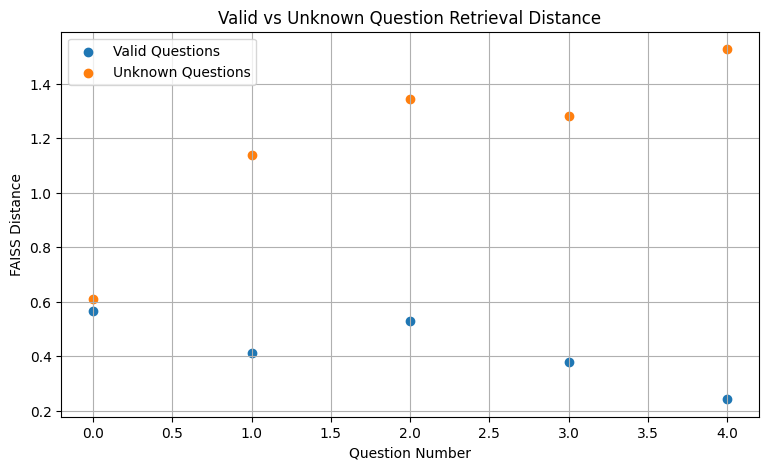

In [ ]:
import matplotlib.pyplot as plt

valid_distances = rag_df["Distance"]
unknown_distances = unknown_df["Distance"]

plt.figure(figsize=(9, 5))

plt.scatter(
    range(len(valid_distances)),
    valid_distances,
    label="Valid Questions"
)

plt.scatter(
    range(len(unknown_distances)),
    unknown_distances,
    label="Unknown Questions"
)

plt.xlabel("Question Number")
plt.ylabel("FAISS Distance")
plt.title("Valid vs Unknown Question Retrieval Distance")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
expected_topics = [
    "refund",
    "support",
    "support",
    "premium",
    "premium"
]

rag_df["Retrieved Correctly"] = [
    topic.lower() in context.lower()
    for topic, context in zip(
        expected_topics,
        rag_df["Retrieved Context"]
    )
]

correct = rag_df["Retrieved Correctly"].sum()
total = len(rag_df)

retrieval_rate = (correct / total) * 100

print("Correct Retrievals:", correct)
print("Total Questions:", total)
print("Retrieval Topic-Match Rate:", retrieval_rate, "%")

display(rag_df[[
    "Question",
    "Retrieved Context",
    "Retrieved Correctly"
]])

Correct Retrievals: 5
Total Questions: 5
Retrieval Topic-Match Rate: 100.0 %


,Question,Retrieved Context,Retrieved Correctly
0,How long do I have to request a refund?,Refunds are allowed within 7 days of purchase.,True
1,Is customer support available all day?,Customer support is available 24/7 via chat.,True
2,How can I contact the support team?,Customers can contact the support team through...,True
3,What does the premium plan include?,The premium plan provides additional customer ...,True
4,Do premium users get priority support?,Premium users can access priority support serv...,True


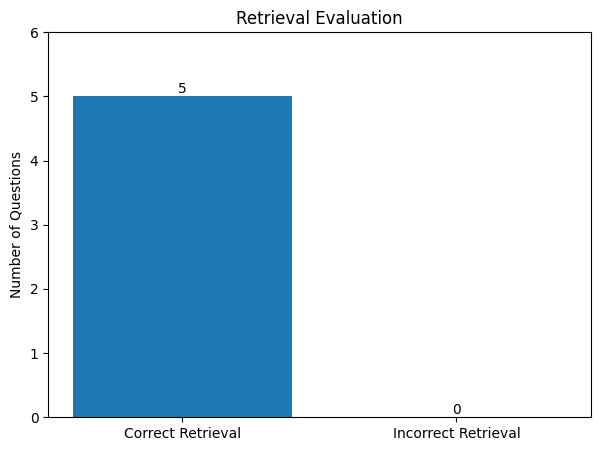

In [ ]:
import matplotlib.pyplot as plt

correct = int(rag_df["Retrieved Correctly"].sum())
incorrect = len(rag_df) - correct

labels = ["Correct Retrieval", "Incorrect Retrieval"]
values = [correct, incorrect]

plt.figure(figsize=(7, 5))

plt.bar(labels, values)

plt.ylabel("Number of Questions")
plt.title("Retrieval Evaluation")

for i, value in enumerate(values):
    plt.text(i, value + 0.05, str(value), ha="center")

plt.ylim(0, max(values) + 1)

plt.show()

In [ ]:
test_questions_10 = [
    "How long do I have to request a refund?",
    "Can I request a refund from customer support?",
    "When should I submit a refund request?",
    "Is customer support available all day?",
    "How can I contact the support team?",
    "What kind of questions can support help with?",
    "What does the premium plan include?",
    "Do premium customers get priority email support?",
    "What support services are available to premium users?",
    "What information should I provide when asking for support?"
]

rag_results_10 = []

for question in test_questions_10:

    results = retrieve(question, k=1)
    context = results[0]["chunk"]
    distance = results[0]["distance"]

    prompt = f"""
Answer the question using only the context below.

Context:
{context}

Question:
{question}

Answer:
"""

    inputs = tokenizer(prompt, return_tensors="pt", truncation=True)

    outputs = generator_model.generate(
        **inputs,
        max_new_tokens=30,
        num_beams=4,
        do_sample=False,
        early_stopping=True
    )

    answer = tokenizer.decode(outputs[0], skip_special_tokens=True)

    rag_results_10.append({
        "Question": question,
        "Retrieved Context": context,
        "Distance": distance,
        "Generated Answer": answer
    })

rag_df_10 = pd.DataFrame(rag_results_10)

print("10-question RAG evaluation completed!")
display(rag_df_10)

10-question RAG evaluation completed!


,Question,Retrieved Context,Distance,Generated Answer
0,How long do I have to request a refund?,Refunds are allowed within 7 days of purchase.,0.564521,within 7 days
1,Can I request a refund from customer support?,Customers can request a refund by contacting c...,0.278697,Yes
2,When should I submit a refund request?,Refund requests must be submitted within the a...,0.493225,within the allowed refund period
3,Is customer support available all day?,Customer support is available 24/7 via chat.,0.411676,24/7
4,How can I contact the support team?,Customers can contact the support team through...,0.529087,through the online chat
5,What kind of questions can support help with?,The support team helps customers with product ...,1.025813,product and account-related
6,What does the premium plan include?,The premium plan provides additional customer ...,0.378346,additional customer support benefits
7,Do premium customers get priority email support?,Premium plans include priority email support.,0.256221,yes
8,What support services are available to premium...,Premium users can access priority support serv...,0.488110,priority support services
9,What information should I provide when asking ...,Customers should provide relevant purchase inf...,0.645235,relevant purchase information


In [ ]:
expected_topics_10 = [
    "refund",
    "refund",
    "refund",
    "support",
    "support",
    "support",
    "premium",
    "premium",
    "premium",
    "purchase"
]

rag_df_10["Retrieved Correctly"] = [
    topic.lower() in context.lower()
    for topic, context in zip(
        expected_topics_10,
        rag_df_10["Retrieved Context"]
    )
]

correct_10 = int(rag_df_10["Retrieved Correctly"].sum())
total_10 = len(rag_df_10)

retrieval_rate_10 = (correct_10 / total_10) * 100

print("Correct Retrievals:", correct_10)
print("Total Questions:", total_10)
print("Retrieval Topic-Match Rate:", retrieval_rate_10, "%")

display(rag_df_10[[
    "Question",
    "Retrieved Context",
    "Retrieved Correctly"
]])

Correct Retrievals: 10
Total Questions: 10
Retrieval Topic-Match Rate: 100.0 %


,Question,Retrieved Context,Retrieved Correctly
0,How long do I have to request a refund?,Refunds are allowed within 7 days of purchase.,True
1,Can I request a refund from customer support?,Customers can request a refund by contacting c...,True
2,When should I submit a refund request?,Refund requests must be submitted within the a...,True
3,Is customer support available all day?,Customer support is available 24/7 via chat.,True
4,How can I contact the support team?,Customers can contact the support team through...,True
5,What kind of questions can support help with?,The support team helps customers with product ...,True
6,What does the premium plan include?,The premium plan provides additional customer ...,True
7,Do premium customers get priority email support?,Premium plans include priority email support.,True
8,What support services are available to premium...,Premium users can access priority support serv...,True
9,What information should I provide when asking ...,Customers should provide relevant purchase inf...,True


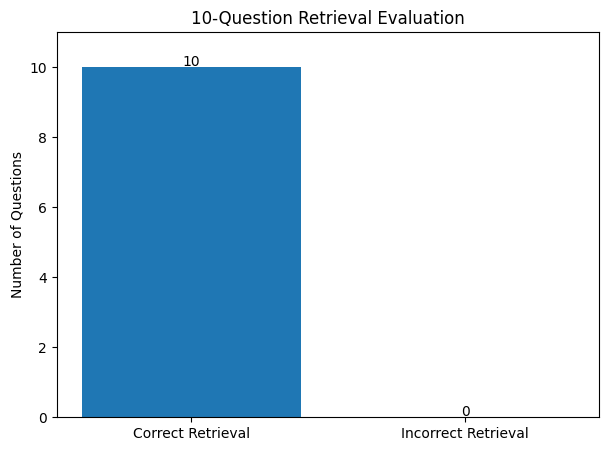

In [ ]:
import matplotlib.pyplot as plt

correct_10 = int(rag_df_10["Retrieved Correctly"].sum())
incorrect_10 = len(rag_df_10) - correct_10

labels = ["Correct Retrieval", "Incorrect Retrieval"]
values = [correct_10, incorrect_10]

plt.figure(figsize=(7, 5))

plt.bar(labels, values)

plt.ylabel("Number of Questions")
plt.title("10-Question Retrieval Evaluation")

for i, value in enumerate(values):
    plt.text(i, value + 0.05, str(value), ha="center")

plt.ylim(0, max(values) + 1)

plt.show()

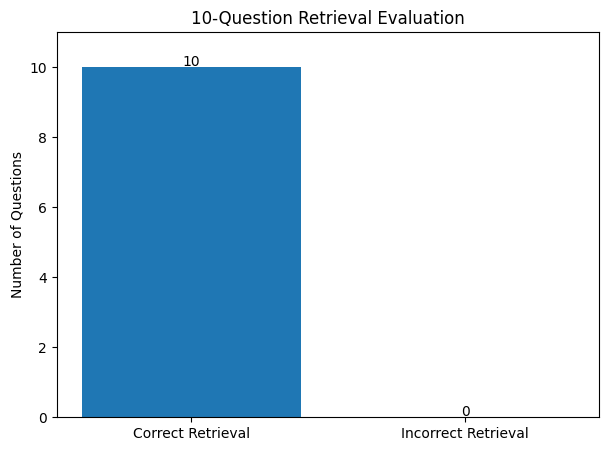

In [ ]:
import matplotlib.pyplot as plt

correct_10 = int(rag_df_10["Retrieved Correctly"].sum())
incorrect_10 = len(rag_df_10) - correct_10

labels = ["Correct Retrieval", "Incorrect Retrieval"]
values = [correct_10, incorrect_10]

plt.figure(figsize=(7, 5))

plt.bar(labels, values)

plt.ylabel("Number of Questions")
plt.title("10-Question Retrieval Evaluation")

for i, value in enumerate(values):
    plt.text(i, value + 0.05, str(value), ha="center")

plt.ylim(0, max(values) + 1)

plt.show()

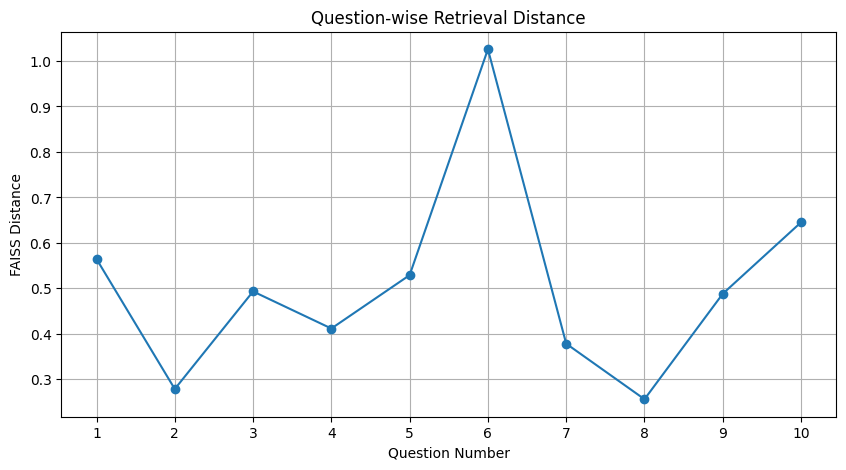

In [ ]:
import matplotlib.pyplot as plt

questions = range(1, len(rag_df_10) + 1)
distances = rag_df_10["Distance"]

plt.figure(figsize=(10, 5))

plt.plot(
    questions,
    distances,
    marker="o"
)

plt.xlabel("Question Number")
plt.ylabel("FAISS Distance")
plt.title("Question-wise Retrieval Distance")

plt.xticks(questions)
plt.grid(True)

plt.show()

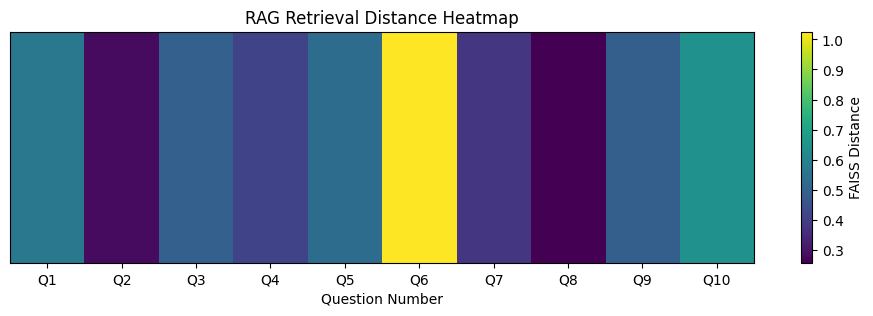

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

distance_matrix = np.array([rag_df_10["Distance"].values])

plt.figure(figsize=(12, 3))

plt.imshow(distance_matrix, aspect="auto")

plt.colorbar(label="FAISS Distance")

plt.xticks(
    range(len(rag_df_10)),
    [f"Q{i}" for i in range(1, len(rag_df_10) + 1)]
)

plt.yticks([])

plt.xlabel("Question Number")
plt.title("RAG Retrieval Distance Heatmap")

plt.show()

In [ ]:
import time

response_times = []

for question in test_questions_10:

    start_time = time.time()

    results = retrieve(question, k=1)
    context = results[0]["chunk"]

    prompt = f"""
Answer the question using only the context below.

Context:
{context}

Question:
{question}

Answer:
"""

    inputs = tokenizer(prompt, return_tensors="pt", truncation=True)

    outputs = generator_model.generate(
        **inputs,
        max_new_tokens=30,
        num_beams=4,
        do_sample=False,
        early_stopping=True
    )

    answer = tokenizer.decode(outputs[0], skip_special_tokens=True)

    end_time = time.time()

    response_times.append(end_time - start_time)

print("Response time measurement completed!")

for i, t in enumerate(response_times, 1):
    print(f"Question {i}: {t:.4f} seconds")

print(f"\nAverage Response Time: {sum(response_times)/len(response_times):.4f} seconds")

Response time measurement completed!
Question 1: 0.9218 seconds
Question 2: 0.6697 seconds
Question 3: 1.0081 seconds
Question 4: 0.5874 seconds
Question 5: 0.7792 seconds
Question 6: 0.8058 seconds
Question 7: 0.6907 seconds
Question 8: 0.2653 seconds
Question 9: 0.4466 seconds
Question 10: 0.4004 seconds

Average Response Time: 0.6575 seconds


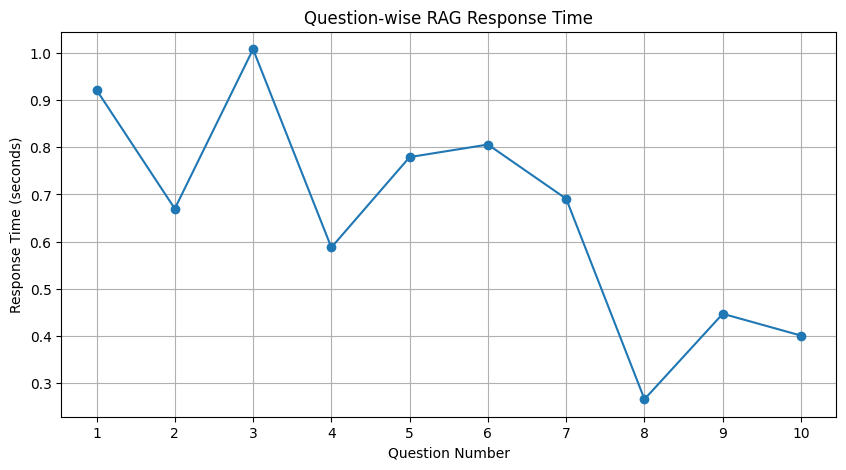

In [ ]:
import matplotlib.pyplot as plt

questions = range(1, len(response_times) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    questions,
    response_times,
    marker="o"
)

plt.xlabel("Question Number")
plt.ylabel("Response Time (seconds)")
plt.title("Question-wise RAG Response Time")

plt.xticks(questions)
plt.grid(True)

plt.show()

In [ ]:
avg_valid_distance = rag_df_10["Distance"].mean()
avg_unknown_distance = unknown_df["Distance"].mean()

print("===== FINAL RAG PERFORMANCE SUMMARY =====")
print("Total Valid Questions:", len(rag_df_10))
print("Correct Retrievals:", correct_10)
print("Retrieval Topic-Match Rate:", f"{retrieval_rate_10:.2f}%")
print("Total Unknown Questions:", len(unknown_df))
print("Average Valid Question Distance:", f"{avg_valid_distance:.4f}")
print("Average Unknown Question Distance:", f"{avg_unknown_distance:.4f}")
print("Average Response Time:", f"{sum(response_times)/len(response_times):.4f} seconds")

===== FINAL RAG PERFORMANCE SUMMARY =====
Total Valid Questions: 10
Correct Retrievals: 10
Retrieval Topic-Match Rate: 100.00%
Total Unknown Questions: 5
Average Valid Question Distance: 0.5071
Average Unknown Question Distance: 1.1808
Average Response Time: 0.6575 seconds


In [ ]:
def rag_answer(question):

    # Step 1: Retrieve relevant document
    results = retrieve(question, k=1)
    context = results[0]["chunk"]

    # Step 2: Create prompt
    prompt = f"""
Answer the question using only the context below.

Context:
{context}

Question:
{question}

Answer:
"""

    # Step 3: Generate answer
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True)

    outputs = generator_model.generate(
        **inputs,
        max_new_tokens=30,
        num_beams=4,
        do_sample=False,
        early_stopping=True
    )

    answer = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return answer, context

In [ ]:
question = input("Enter your question: ")

answer, context = rag_answer(question)

print("\nRetrieved Context:")
print(context)

print("\nGenerated Answer:")
print(answer)

Enter your question: How long do I have to request a refund?

Retrieved Context:
Refunds are allowed within 7 days of purchase.

Generated Answer:
within 7 days


In [ ]:
question = input("Enter your question: ")

answer, context = rag_answer(question)

print("\nRetrieved Context:")
print(context)

print("\nGenerated Answer:")
print(answer)

Enter your question: What kind of support does the premium plan provide?

Retrieved Context:
The premium plan provides additional customer support benefits.

Generated Answer:
additional customer support benefits


In [ ]:
question = input("Enter your question: ")

answer, context = rag_answer(question)

print("\nRetrieved Context:")
print(context)

print("\nGenerated Answer:")
print(answer)

Enter your question: What is the price of the premium plan?

Retrieved Context:
The premium plan provides additional customer support benefits.

Generated Answer:
a).


In [ ]:
def rag_answer(question):

    # Step 1: Retrieve relevant document
    results = retrieve(question, k=1)
    context = results[0]["chunk"]

    # Step 2: Improved prompt
    prompt = f"""
You are a question-answering system.

Use ONLY the information given in the context.

If the answer is not explicitly present in the context,
reply exactly:
"Information not available in the knowledge base."

Do not guess or make up information.

Context:
{context}

Question:
{question}

Answer:
"""

    # Step 3: Generate answer
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True
    )

    outputs = generator_model.generate(
        **inputs,
        max_new_tokens=30,
        num_beams=4,
        do_sample=False,
        early_stopping=True
    )

    answer = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return answer, context

print("Improved RAG function created successfully!")

Improved RAG function created successfully!


In [ ]:
question = "What is the price of the premium plan?"

answer, context = rag_answer(question)

print("Question:", question)

print("\nRetrieved Context:")
print(context)

print("\nGenerated Answer:")
print(answer)

Question: What is the price of the premium plan?

Retrieved Context:
The premium plan provides additional customer support benefits.

Generated Answer:
premium plan
